# Trigram loss: theory versus numerical results

This notebook reproduces the **two-panel, fixed-\(f\)** trigram-loss figure used in the paper. It compares the exact numerical trigram conditional entropy for varying-tree RHM grammars to the large-\(vf\) prediction

\[\frac{\ln(vf)+(1-f)\ln 2}{\ln v}.\]

The panels use \(f=1/4\) and \(f=1/2\); the numerical results average over independently generated grammars. The lines in the background show individual seeds, and error bars show **one standard deviation across grammars**, not the standard error of the mean.

This version removes superseded formula comparisons and exploratory analyses. The figure displayed at the end is retained from the original notebook; rerun the cells to regenerate it. The full numerical sweep may take significant time, especially at large \(v\).

In [ ]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

# Locate the original grammar-generation implementation.
import sys

candidates = [
    Path.cwd() / "parsing/inside_outside/For_training",
    Path.cwd().parent / "parsing/inside_outside/For_training",
]

for directory in candidates:
    if (directory / "Inside_outside.py").is_file():
        sys.path.insert(0, str(directory.resolve()))
        break
else:
    raise FileNotFoundError(
        "Cannot locate parsing/inside_outside/For_training/Inside_outside.py"
    )

from Inside_outside import generate_grammar, generate_rules_double_new

DEPTH = 3
TARGET_F_VALUES = [1/4, 1/2]
TARGET_V_VALUES = [4, 6, 8, 16, 32, 64]
TARGET_SEEDS = [12345678, 12345679, 12345680]
V4_SEEDS = list(range(12345678, 12345778))  # 100 grammars at V=4
DATA_PATH = Path("Last_token_trigram_fixed_f_data.json")


## Exact trigram loss for a sampled grammar

For a fixed grammar, the recursion below constructs the joint distribution of the last three terminal symbols, marginalizing over the compatible derivations. It then computes \(H(x_d\mid x_{d-2},x_{d-1})\) without Monte Carlo sampling of sentences.

In [ ]:
def conditional_entropy_from_counts(counts):
    """H(C|A,B), where counts can be an unnormalized joint distribution."""
    context_counts = counts.sum(axis=2, keepdims=True)
    probabilities = np.divide(
        counts, context_counts, out=np.zeros_like(counts, dtype=float),
        where=context_counts > 0,
    )
    log_probabilities = np.zeros_like(probabilities)
    np.log(probabilities, out=log_probabilities, where=probabilities > 0)
    context_entropies = -(probabilities * log_probabilities).sum(axis=2)
    context_weights = context_counts[..., 0] / counts.sum()
    return float((context_weights * context_entropies).sum())


def exact_final_trigram_distribution(grammar, v, depth):
    if depth < 2:
        raise ValueError('Use depth >= 2 so every sentence has at least three tokens.')
    last = np.zeros((v, v))
    short = np.zeros((v, v, v))
    suffix = np.zeros((v, v, v, v))
    # At the bottom, a production yields either two or three terminals.
    for lhs, productions in grammar[f'layer{depth}'].items():
        parent = (int(lhs) - 1) % v
        total = sum(prob for _, prob in productions)
        for rhs, prob in productions:
            children = tuple((int(x) - 1) % v for x in rhs)
            weight = prob / total
            last[parent, children[-1]] += weight
            if len(children) == 2:
                short[(parent,) + children] += weight
            else:
                suffix[(parent,) + children] += weight
    for layer in range(depth - 1, 0, -1):
        transition = np.zeros((v, v))
        pair_transition = np.zeros((v, v, v))
        for lhs, productions in grammar[f'layer{layer}'].items():
            parent = (int(lhs) - 1) % v
            total = sum(prob for _, prob in productions)
            for rhs, prob in productions:
                previous, final = [(int(x) - 1) % v for x in rhs[-2:]]
                transition[parent, final] += prob / total
                pair_transition[parent, previous, final] += prob / total
        new_suffix = np.einsum('ij,jabc->iabc', transition, suffix, optimize=True)
        if np.any(short):
            new_suffix += np.einsum(
                'ijk,ja,kbc->iabc', pair_transition, last, short, optimize=True
            )
        last = transition @ last
        suffix = new_suffix
        short = np.zeros_like(short)  # Every higher-layer yield has >= 4 terminals.
    joint = suffix.mean(axis=0)  # Same uniform start-symbol prior as the sampler.
    np.testing.assert_allclose(joint.sum(), 1.0, atol=1e-12)
    return joint

## Numerical comparison across vocabularies

For each valid \((v,f)\), the rule multiplicities are \(m_2=fv\), \(m_3=fv^2\), with binary and ternary productions each chosen with total probability \(1/2\). At \(v=4\) we average over 100 grammar realizations; otherwise we use three. Results are cached in `Last_token_trigram_fixed_f_data.json` in the working directory. The cache is used only for matching parameters and the exact seed list.

In [ ]:
valid_pairs = {
    (v, f) for f in TARGET_F_VALUES for v in TARGET_V_VALUES
    if np.isclose(f*v, round(f*v)) and np.isclose(f*v**2, round(f*v**2))
}

cached_results = {}
if DATA_PATH.exists():
    saved = json.loads(DATA_PATH.read_text())
    if (saved.get("depth") == DEPTH and saved.get("eta_generation") == "V"
            and saved.get("start_symbol_prior") == "uniform"):
        cached_results = {(r["V"], r["F"]): r for r in saved["results"]}

comparison_results = []
for f in TARGET_F_VALUES:
    for v in TARGET_V_VALUES:
        if (v, f) not in valid_pairs:
            print(f"Skipping v={v}, f={f}: noninteger rule counts")
            continue
        seeds = V4_SEEDS if v == 4 else TARGET_SEEDS
        cached = cached_results.get((v, f), {})
        cached_losses = dict(zip(cached.get("grammar_seeds", []), cached.get("entropies", [])))
        m2, m3 = round(f*v), round(f*v**2)
        p3 = 1 / (m2*v + m3)
        p2 = v*p3
        entropies = []
        for seed in seeds:
            if seed in cached_losses:
                entropies.append(cached_losses[seed])
                continue
            rules, _ = generate_rules_double_new(v, v, m2, m3, p2, p3, DEPTH, seed)
            joint = exact_final_trigram_distribution(generate_grammar(rules), v, DEPTH)
            entropies.append(conditional_entropy_from_counts(joint))
            del rules, joint
        comparison_results.append(dict(
            V=v, F=f, numerical=float(np.mean(entropies)),
            std=float(np.std(entropies, ddof=1)) if len(entropies) > 1 else 0.0,
            entropies=entropies, grammar_seeds=seeds,
        ))
        print(f"Done: v={v}, f={f}, grammars={len(seeds)}")

for r in comparison_results:
    v, f = r["V"], r["F"]
    r["large_v_theory"] = float(np.log(v*f) + (1-f)*np.log(2))
comparison_results.sort(key=lambda r: (r["F"], r["V"]))

DATA_PATH.write_text(json.dumps(dict(
    depth=DEPTH, eta_generation="V", start_symbol_prior="uniform",
    results=[{k: val for k, val in r.items() if k != "large_v_theory"}
             for r in comparison_results],
), indent=2) + "\n")
print(f"Saved numerical data to {DATA_PATH.resolve()}")


## Figure: trigram loss versus vocabulary size

Each panel shows the normalized exact numerical loss, individual grammar realizations, and the large-\(vf\) prediction. The theoretical curve is not drawn when its normalized value exceeds 1.

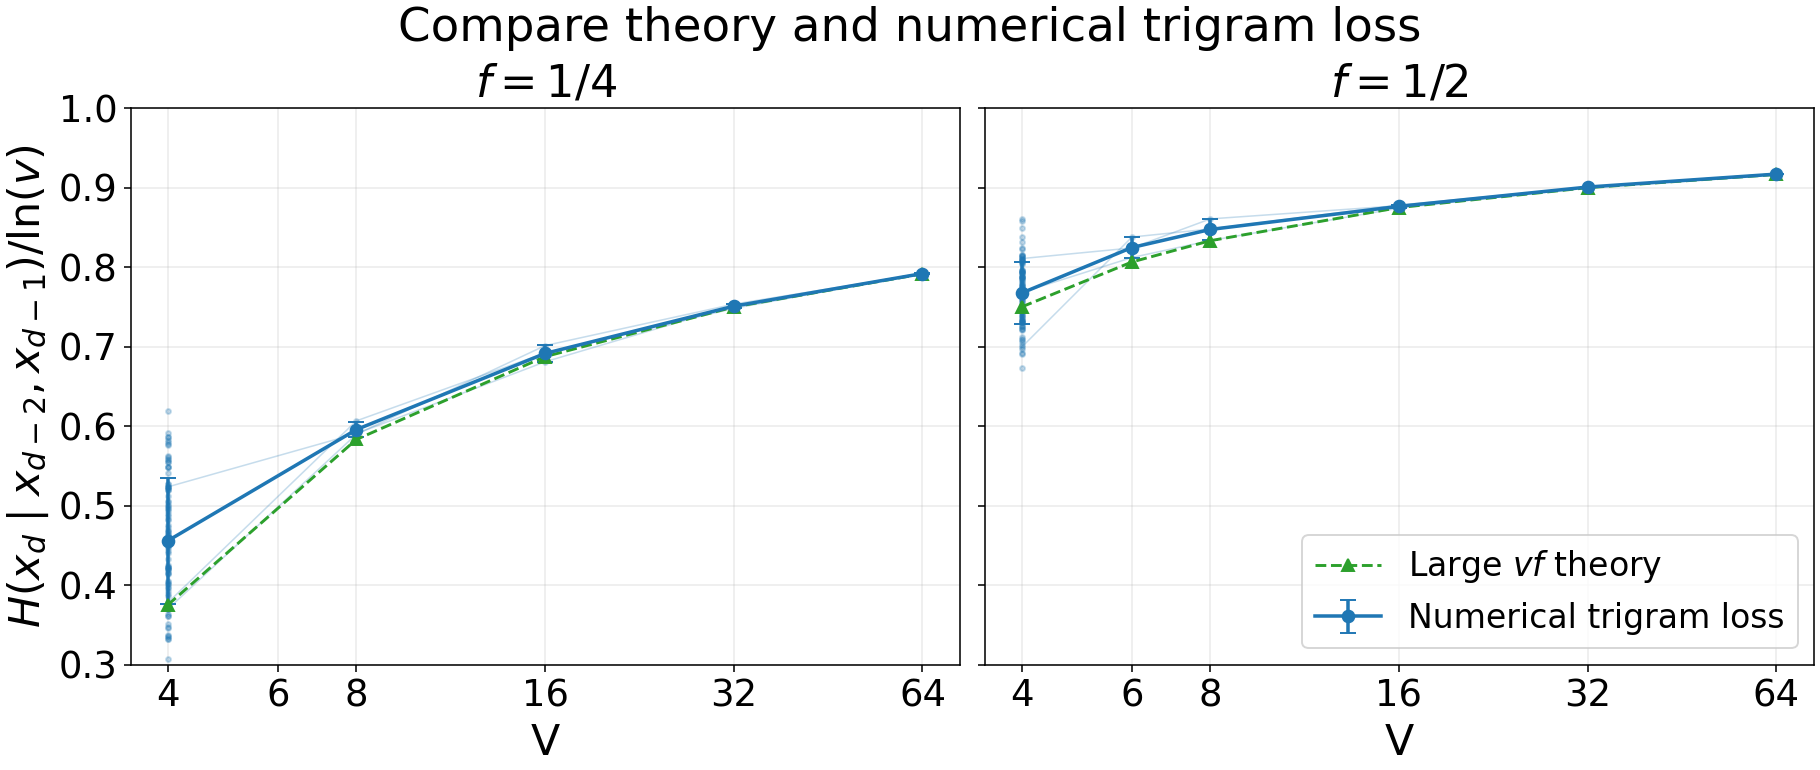

In [ ]:
fig_fixed_f, axes_fixed_f = plt.subplots(
    1, len(TARGET_F_VALUES), figsize=(13, 5.5), sharex=True, sharey=True,
    constrained_layout=True, squeeze=False,
)
for ax, f in zip(axes_fixed_f[0], TARGET_F_VALUES):
    rows = sorted((r for r in comparison_results if np.isclose(r['F'], f)),
                  key=lambda r: r['V'])
    vs = np.array([r['V'] for r in rows])
    scale = np.log(vs)
    exact = np.array([r['numerical'] for r in rows]) / scale
    std = np.array([r['std'] for r in rows]) / scale
    # Seed counts may differ by V; NaNs keep unobserved seed values unconnected.
    seed_ids = sorted({seed for r in rows for seed in r.get('grammar_seeds', TARGET_SEEDS)})
    seed_values = np.full((len(rows), len(seed_ids)), np.nan)
    for row_index, r in enumerate(rows):
        for seed, loss in zip(r.get('grammar_seeds', TARGET_SEEDS), r['entropies']):
            seed_values[row_index, seed_ids.index(seed)] = loss / scale[row_index]
    ax.plot(vs, seed_values, color='C0', alpha=0.25, linewidth=0.8,
            marker='.', markersize=5)
    ax.errorbar(vs, exact, yerr=std, fmt='o-', color='C0', capsize=4,
                linewidth=1.8, label='Numerical trigram loss')
    large_v = np.array([r['large_v_theory'] for r in rows]) / scale
    ax.plot(vs, np.where(large_v <= 1, large_v, np.nan), '^--', color='C2',
            label=r'Large $vf$ theory')
    ax.set_title(r'$f=1/4$' if np.isclose(f, 1/4) else r'$f=1/2$', fontsize=23)
    ax.set_xscale('log', base=2)
    ax.set_xticks(TARGET_V_VALUES, labels=[str(v) for v in TARGET_V_VALUES])
    ax.set_xlabel('V', fontsize=22)
    ax.tick_params(axis='both', labelsize=19)
    ax.set_ylim(0.3, 1)
    ax.set_xlim(left=3.5)
    ax.grid(alpha=0.25)
axes_fixed_f[0, 0].set_ylabel(r'$H(x_d\mid x_{d-2},x_{d-1})/\ln(v)$', fontsize=22)
axes_fixed_f[0, -1].legend(fontsize=17, loc='lower right')
fig_fixed_f.suptitle('Compare theory and numerical trigram loss', fontsize=24)
plt.show()
